<a href="https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2a_vetores2d_algebra.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Abrir no Colab"/></a>

# Domínio II (a): a álgebra dos vetores do plano

## Pontos e vetores, os produtos que existem e os que faltam, geometria no computador, e a interface de domínio em ℝ²

**Série:** [raiz](X0_raiz.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X0_raiz.ipynb)) · **Domínio:** [nó 2](X2_vetores2d.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2_vetores2d.ipynb)) · **Próximo:** [X2b_vetores2d_sistemas.ipynb](X2b_vetores2d_sistemas.ipynb) ([Colab](https://colab.research.google.com/github/saulobortolon/Quaternios-Kalman-CC/blob/main/dominios/notebooks/X2b_vetores2d_sistemas.ipynb))

**Objetivo.** Passar da reta ao plano. Um ponto do plano tem duas coordenadas, $(x,y)\in\mathbb R^2$, e quase tudo do domínio I continua valendo coordenada a coordenada. O interessante é o que **não** continua:
- não existe uma multiplicação de vetores que faça de ℝ² um corpo "de graça". As escolhas possíveis de produto levam a três estruturas diferentes, e duas delas são os domínios III e IV desta série;
- não existe uma ordem natural: "o ponto $p$ é menor que o ponto $q$" deixa de fazer sentido;
- aparecem perguntas **geométricas** (de que lado de uma reta está um ponto?), e o `float` responde errado a algumas delas.

**Pontos e vetores não são a mesma coisa.** Uma posição (um **ponto**) e um deslocamento (um **vetor**) se escrevem ambos como pares de números, mas obedecem a regras diferentes. Esta distinção, que em ℝ passa despercebida, organiza o resto da série: o estado de um objeto é um "ponto" de um grupo de movimentos, e os incrementos $\delta$ do filtro de Kalman são "vetores".

**Roteiro**
1. Vetores: os axiomas de espaço vetorial, conferidos pelo `sympy`
2. Pontos: o espaço afim, e por que não se somam dois pontos
3. Os produtos de ℝ²: escalar, determinante, componente a componente, e a família que leva aos duais e aos complexos
4. Norma, ângulo e ordem
5. Geometria no computador: de que lado da reta? O `float` contra a aritmética exata
6. Transformações do plano: translações (o grupo deste domínio) e transformações lineares
7. A interface de domínio em ℝ²
8. Exercícios

In [1]:
# Ferramentas comuns da série (repetidas em todos os notebooks, para que cada um rode sozinho no Colab)
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=6, suppress=True)
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 100,
                     "axes.spines.top": False, "axes.spines.right": False})

def confere(nome, obtido, esperado, tol=1e-9, relativo=False):
    """Compara duas quantidades. Imprime OK ou interrompe o notebook com uma mensagem clara."""
    a, b = np.asarray(obtido, dtype=float), np.asarray(esperado, dtype=float)
    escala = max(np.max(np.abs(b)), 1e-300) if relativo else 1.0
    erro = float(np.max(np.abs(a - b)) / escala)
    ok = erro <= tol
    print(f"{'OK ' if ok else 'FALHOU'}  {nome}:  diferença {'relativa ' if relativo else ''}máxima = {erro:.2e}")
    assert ok, f"conferência falhou: {nome}"

import sympy as sp
from fractions import Fraction
import math
rng = np.random.default_rng(21)

---

## 1. Vetores: os axiomas de espaço vetorial

Um **espaço vetorial** real é um conjunto com uma soma de vetores e uma multiplicação de um **número** por um vetor, com oito regras. Para $\mathbf u,\mathbf v,\mathbf w\in\mathbb R^2$ e $a,b\in\mathbb R$:

| regra | enunciado |
|---|---|
| associatividade da soma | $(\mathbf u+\mathbf v)+\mathbf w=\mathbf u+(\mathbf v+\mathbf w)$ |
| comutatividade da soma | $\mathbf u+\mathbf v=\mathbf v+\mathbf u$ |
| vetor nulo | $\mathbf v+\mathbf 0=\mathbf v$ |
| oposto | $\mathbf v+(-\mathbf v)=\mathbf 0$ |
| compatibilidade | $a(b\mathbf v)=(ab)\mathbf v$ |
| identidade | $1\,\mathbf v=\mathbf v$ |
| distributividade (vetores) | $a(\mathbf u+\mathbf v)=a\mathbf u+a\mathbf v$ |
| distributividade (números) | $(a+b)\mathbf v=a\mathbf v+b\mathbf v$ |

Repare no que **não** está na lista: nenhuma regra multiplica dois vetores entre si. A multiplicação de ℝ² é sempre "número vezes vetor". Com as operações feitas coordenada a coordenada, as oito regras são herdadas diretamente de ℝ, como o `sympy` confirma.

In [2]:
u1, u2, v1, v2, w1, w2, a, b = sp.symbols("u1 u2 v1 v2 w1 w2 a b", real=True)
u, v, w = sp.Matrix([u1, u2]), sp.Matrix([v1, v2]), sp.Matrix([w1, w2])
zero = sp.zeros(2, 1)
regras = {
    "associatividade da soma":     (u + v) + w - (u + (v + w)),
    "comutatividade da soma":      u + v - (v + u),
    "vetor nulo":                  v + zero - v,
    "oposto":                      v + (-v) - zero,
    "compatibilidade":             a * (b * v) - (a * b) * v,
    "identidade":                  1 * v - v,
    "distributividade (vetores)":  a * (u + v) - (a * u + a * v),
    "distributividade (números)":  (a + b) * v - (a * v + b * v),
}
for nome, expr in regras.items():
    print(f"{nome:28s} → {list(sp.simplify(expr))}")

associatividade da soma      → [0, 0]
comutatividade da soma       → [0, 0]
vetor nulo                   → [0, 0]
oposto                       → [0, 0]
compatibilidade              → [0, 0]
identidade                   → [0, 0]
distributividade (vetores)   → [0, 0]
distributividade (números)   → [0, 0]


**Em `float`,** cada coordenada sofre os mesmos arredondamentos do domínio I: a soma de vetores é comutativa e não é associativa. Nada de novo, e por isso a série não repete o experimento. A novidade do plano está nas próximas seções.

---

## 2. Pontos: o espaço afim

Uma **posição** no plano (onde está Penélope) não é um deslocamento (quanto ela andou). As operações que fazem sentido entre posições e deslocamentos são poucas:

| operação | resultado | exemplo |
|---|---|---|
| ponto $-$ ponto | vetor | $q-p$: o deslocamento que leva de $p$ a $q$ |
| ponto $+$ vetor | ponto | $p+\mathbf v$: andar $\mathbf v$ a partir de $p$ |
| vetor $\pm$ vetor | vetor | somar dois deslocamentos |
| ponto $+$ ponto | **não faz sentido** | depende de onde se pôs a origem |

O teste do que faz sentido é **mudar a origem** do sistema de coordenadas. Um resultado com significado físico não pode depender dessa escolha arbitrária. Com uma origem nova, deslocada de $\mathbf o$, as coordenadas de todos os pontos mudam para $p'=p-\mathbf o$:
- $q'-p'=(q-\mathbf o)-(p-\mathbf o)=q-p$: o vetor entre dois pontos **não muda**;
- $p'+q'=p+q-2\mathbf o$: a "soma de pontos" **muda**, e por isso não significa nada.

**Combinações afins.** Há uma exceção útil: a combinação $\lambda_1p_1+\dots+\lambda_np_n$ é um ponto bem definido quando os pesos somam 1. O ponto médio ($\tfrac12p+\tfrac12q$) e o baricentro de um triângulo ($\tfrac13$ de cada vértice) são exemplos. Com pesos que somam 1, a origem se cancela.

In [3]:
p, q, r_ = np.array([3.0, 1.0]), np.array([7.0, 4.0]), np.array([2.0, 6.0])
o = np.array([100.0, -50.0])                      # uma origem nova, arbitrária
nova = lambda x: x - o                             # coordenadas na origem nova

confere("q − p não depende da origem", nova(q) - nova(p), q - p)
print("p + q nas duas origens:", p + q, "e", nova(p) + nova(q) + o, " ← diferentes: soma de pontos não tem sentido")
confere("o ponto médio (pesos 1/2 + 1/2) não depende da origem", (nova(p) + nova(q)) / 2 + o, (p + q) / 2)
confere("o baricentro (pesos 1/3 cada) não depende da origem", (nova(p) + nova(q) + nova(r_)) / 3 + o, (p + q + r_) / 3)

# simbolicamente: uma combinação de pontos independe da origem exatamente quando os pesos somam 1
l1, l2, l3, o1, o2 = sp.symbols("lambda1 lambda2 lambda3 o1 o2", real=True)
P = [sp.Matrix(sp.symbols(f"p{i}x p{i}y", real=True)) for i in range(3)]
O = sp.Matrix([o1, o2])
comb = lambda pts, ls: sum((l * x for l, x in zip(ls, pts)), sp.zeros(2, 1))
dif = sp.simplify(comb([x - O for x in P], [l1, l2, l3]) + O - comb(P, [l1, l2, l3]))
print("diferença entre as duas origens:", list(dif), " → zero se e só se λ1 + λ2 + λ3 = 1")

OK   q − p não depende da origem:  diferença máxima = 0.00e+00
p + q nas duas origens: [10.  5.] e [-90.  55.]  ← diferentes: soma de pontos não tem sentido
OK   o ponto médio (pesos 1/2 + 1/2) não depende da origem:  diferença máxima = 0.00e+00
OK   o baricentro (pesos 1/3 cada) não depende da origem:  diferença máxima = 2.22e-15
diferença entre as duas origens: [o1*(-lambda1 - lambda2 - lambda3 + 1), o2*(-lambda1 - lambda2 - lambda3 + 1)]  → zero se e só se λ1 + λ2 + λ3 = 1


> **Nota: por que isso importa para a série.** No filtro de Kalman, o estado (onde está o alvo) é um "ponto", e a correção $\mathbf K\nu$ é um "vetor" somado a ele. Em ℝ², ponto mais vetor é a soma de coordenadas, e a distinção parece pedante. A partir do domínio V, o estado será uma **pose** (posição e atitude), e a correção continuará sendo um vetor pequeno: a regra "ponto $+$ vetor" passa a ser $x\boxplus\delta$, e já não é uma soma.

---

## 3. Os produtos de ℝ²

O que acontece se tentarmos inventar um produto de dois vetores? Há quatro candidatos naturais, e cada um perde alguma coisa.

| produto | fórmula para $\mathbf u=(u_1,u_2)$, $\mathbf v=(v_1,v_2)$ | resultado | o que perde |
|---|---|---|---|
| escalar | $\mathbf u\cdot\mathbf v=u_1v_1+u_2v_2$ | um número | não é um produto *em* ℝ² (sai do conjunto) |
| determinante ("produto vetorial" no plano) | $\mathbf u\times\mathbf v=u_1v_2-u_2v_1$ | um número | idem; e é anticomutativo |
| componente a componente | $(u_1v_1,\ u_2v_2)$ | um vetor | inversos: $(1,0)\cdot(0,1)=(0,0)$ |
| a família $(a,b)(c,d)=(ac+\alpha\,bd,\ ad+bc)$ | depende de $\alpha$ | um vetor | ver abaixo |

**Os dois primeiros** são as ferramentas da geometria: o escalar mede **ângulos e comprimentos** ($\mathbf u\cdot\mathbf v=\|\mathbf u\|\|\mathbf v\|\cos\theta$), o determinante mede **áreas orientadas** ($\mathbf u\times\mathbf v=\|\mathbf u\|\|\mathbf v\|\sin\theta$, a área do paralelogramo com sinal). A seção 5 usa o determinante.

**O terceiro** tem **divisores de zero**: dois vetores não nulos cujo produto é zero. Num sistema assim não se pode "dividir", e a regra "se $ab=0$, então $a=0$ ou $b=0$" falha.

**A família de produtos.** Escrevendo um vetor como $a+b\,\mathbf e$, com um símbolo $\mathbf e$ tal que $\mathbf e^2=\alpha$, o produto distributivo dá exatamente $(a+b\mathbf e)(c+d\mathbf e)=(ac+\alpha bd)+(ad+bc)\mathbf e$. A menos de uma mudança de escala de $\mathbf e$, só há três casos:

| $\alpha$ | $\mathbf e^2$ | nome | estrutura | aparece em |
|---|---|---|---|---|
| $-1$ | $i^2=-1$ | **números complexos** | corpo (todo não nulo tem inverso) | domínio IV |
| $0$ | $\varepsilon^2=0$ | **números duais** | anel com divisores de zero | domínio III |
| $+1$ | $j^2=+1$ | números hiperbólicos (ou *split-complex*) | anel com divisores de zero | fora da série |

O teste é a "norma" $N(a+b\mathbf e)=a^2-\alpha b^2$, que é **multiplicativa**, $N(xy)=N(x)N(y)$. O inverso existe quando $N\neq0$, e os divisores de zero são os não nulos com $N=0$. Com $\alpha=-1$, $N=a^2+b^2$ só zera na origem.

In [4]:
A_, B_, C_, D_, al = sp.symbols("a b c d alpha", real=True)
def prod(x, y, alpha):
    (a, b), (c, d) = x, y
    return (a * c + alpha * b * d, a * d + b * c)
N = lambda x, alpha: x[0]**2 - alpha * x[1]**2

x, y = (A_, B_), (C_, D_)
print("N(xy) − N(x)N(y) =", sp.simplify(N(prod(x, y, al), al) - N(x, al) * N(y, al)), "  (multiplicativa para qualquer α)")
print("comutatividade:   ", [sp.simplify(e) for e in (sp.Matrix(prod(x, y, al)) - sp.Matrix(prod(y, x, al)))])
for alpha, nome in [(-1, "complexos"), (0, "duais"), (1, "hiperbólicos")]:
    nulos = sp.solve(sp.Eq(N((A_, B_), alpha), 0), A_)
    print(f"\nα = {alpha} ({nome}): N = {N((A_, B_), alpha)};  N = 0 quando a = {nulos}")
    inv = (A_ / N((A_, B_), alpha), -B_ / N((A_, B_), alpha))       # o "conjugado" dividido pela norma
    print("   x · x⁻¹ =", [sp.simplify(e) for e in prod((A_, B_), inv, alpha)])

# divisores de zero, conferidos numericamente
confere("componente a componente: (1,0)·(0,1) = (0,0)", np.array([1, 0]) * np.array([0, 1]), [0, 0])
confere("duais: (0,1)·(0,1) = (0,0), isto é, ε² = 0", prod((0, 1), (0, 1), 0), [0, 0])
confere("hiperbólicos: (1,1)·(1,−1) = (0,0)", prod((1, 1), (1, -1), 1), [0, 0])
confere("complexos: (a,b)·(c,d) = produto do Python", prod((3, 2), (-1, 5), -1), [((3 + 2j) * (-1 + 5j)).real, ((3 + 2j) * (-1 + 5j)).imag])

N(xy) − N(x)N(y) = 0   (multiplicativa para qualquer α)
comutatividade:    [0, 0]

α = -1 (complexos): N = a**2 + b**2;  N = 0 quando a = [-I*b, I*b]
   x · x⁻¹ = [1, 0]

α = 0 (duais): N = a**2;  N = 0 quando a = [0]
   x · x⁻¹ = [1, 0]

α = 1 (hiperbólicos): N = a**2 - b**2;  N = 0 quando a = [-b, b]
   x · x⁻¹ = [1, 0]
OK   componente a componente: (1,0)·(0,1) = (0,0):  diferença máxima = 0.00e+00
OK   duais: (0,1)·(0,1) = (0,0), isto é, ε² = 0:  diferença máxima = 0.00e+00
OK   hiperbólicos: (1,1)·(1,−1) = (0,0):  diferença máxima = 0.00e+00
OK   complexos: (a,b)·(c,d) = produto do Python:  diferença máxima = 0.00e+00


**Leitura.** Para qualquer $\alpha$, o produto é comutativo e a norma é multiplicativa. O inverso é "o conjugado dividido pela norma", $x^{-1}=(a-b\mathbf e)/N(x)$, e existe sempre que $N\neq0$. Só com $\alpha=-1$ a norma é zero apenas na origem: **os complexos são o único modo de dar a ℝ² uma divisão**. Com $\alpha=0$, os vetores $(0,b)$, isto é, $b\varepsilon$, não têm inverso: é o preço dos números duais, que em troca darão derivadas exatas (domínio III).

A série segue a escada: o domínio II fica com ℝ² **sem** produto (só translações), o III escolhe $\alpha=0$ e o IV escolhe $\alpha=-1$.

---

## 4. Norma, ângulo e ordem

**A norma euclidiana** $\|\mathbf v\|=\sqrt{v_1^2+v_2^2}$ é a distância de Pitágoras. Ela satisfaz a desigualdade triangular, $\|\mathbf u+\mathbf v\|\le\|\mathbf u\|+\|\mathbf v\|$, e é **invariante por rotações**. Em `float`, há duas armadilhas na conta ingênua:
- **transbordamento:** com coordenadas da ordem de $10^{200}$, os quadrados passam do maior `float` ($\approx1{,}8\times10^{308}$) e a conta dá infinito, embora a norma caiba folgadamente;
- **subtransbordamento:** com coordenadas da ordem de $10^{-200}$, os quadrados viram zero.

`math.hypot` (e `np.hypot`) reescala antes de elevar ao quadrado. É a mesma ideia da seção 3 do notebook I(a): reescrever a conta para não perder dígitos.

**O ângulo** de um vetor é o $\theta$ tal que $\mathbf v=\|\mathbf v\|(\cos\theta,\sin\theta)$. A fórmula de escola, $\arctan(v_2/v_1)$, só devolve ângulos entre $-90°$ e $90°$: não distingue $(1,1)$ de $(-1,-1)$, e falha com $v_1=0$. A função `atan2(v2, v1)` usa os **dois** sinais e devolve o ângulo certo em $(-180°,180°]$.

In [5]:
for escala in [1.0, 1e200, 1e-200]:
    vx, vy = 3.0 * escala, 4.0 * escala
    ingenua = math.sqrt(vx * vx + vy * vy)
    print(f"v = (3, 4)·{escala:.0e}:  √(x²+y²) = {ingenua:.6e}   hypot = {math.hypot(vx, vy):.6e}   (certo: {5 * escala:.6e})")
confere("hypot acerta onde a fórmula ingênua transborda", math.hypot(3e200, 4e200), 5e200, tol=1e-15, relativo=True)

print()
for vv in [(1, 1), (-1, -1), (-1, 1), (0, 2), (0, -2)]:
    ing = math.degrees(math.atan(vv[1] / vv[0])) if vv[0] != 0 else float("nan")
    print(f"v = {str(vv):9s}  atan(y/x) = {ing:7.1f}°   atan2(y, x) = {math.degrees(math.atan2(vv[1], vv[0])):7.1f}°")
confere("atan2 distingue (1,1) de (−1,−1)", math.atan2(-1, -1), -3 * math.pi / 4, tol=1e-15)

v = (3, 4)·1e+00:  √(x²+y²) = 5.000000e+00   hypot = 5.000000e+00   (certo: 5.000000e+00)
v = (3, 4)·1e+200:  √(x²+y²) = inf   hypot = 5.000000e+200   (certo: 5.000000e+200)
v = (3, 4)·1e-200:  √(x²+y²) = 0.000000e+00   hypot = 5.000000e-200   (certo: 5.000000e-200)
OK   hypot acerta onde a fórmula ingênua transborda:  diferença relativa máxima = 1.36e-16

v = (1, 1)     atan(y/x) =    45.0°   atan2(y, x) =    45.0°
v = (-1, -1)   atan(y/x) =    45.0°   atan2(y, x) =  -135.0°
v = (-1, 1)    atan(y/x) =   -45.0°   atan2(y, x) =   135.0°
v = (0, 2)     atan(y/x) =     nan°   atan2(y, x) =    90.0°
v = (0, -2)    atan(y/x) =     nan°   atan2(y, x) =   -90.0°
OK   atan2 distingue (1,1) de (−1,−1):  diferença máxima = 0.00e+00


**E a ordem?** Em ℝ, todo par de números se compara: $a<b$, $a=b$ ou $a>b$, e a ordem combina com as contas ($a\le b\Rightarrow a+c\le b+c$). No plano não há uma ordem assim com significado geométrico:
- a ordem **componente a componente** ($\mathbf u\le\mathbf v$ se $u_1\le v_1$ e $u_2\le v_2$) é só **parcial**: $(1,0)$ e $(0,1)$ não se comparam;
- a ordem **lexicográfica** (primeiro por $x$, empate decidido por $y$) é total, e é o que o Python usa para ordenar tuplas. Mas ela muda com uma rotação dos eixos, e por isso não diz nada sobre a geometria.

O que sobra é comparar **normas** (distâncias) ou **ângulos**. Um sensor de distância e um sensor de direção, as duas metades dessa informação, são os personagens da etapa (d).

---

## 5. Geometria no computador: de que lado da reta?

A pergunta mais básica da geometria computacional: dados três pontos $p,q,r$, o caminho $p\to q\to r$ vira à **esquerda**, à **direita**, ou os três estão **alinhados**? A resposta é o sinal do determinante

$$\mathrm{orient}(p,q,r)=(q-p)\times(r-p)=(q_x-p_x)(r_y-p_y)-(q_y-p_y)(r_x-p_x),$$

o dobro da área orientada do triângulo $pqr$. Positivo: esquerda (sentido anti-horário). Negativo: direita. Zero: alinhados. Algoritmos de fecho convexo, triangulação, interseção de segmentos e "o ponto está dentro do polígono?" são feitos quase só com este teste.

**A área de um polígono** sai da mesma conta, somando os triângulos que cada aresta forma com a origem (a fórmula do "cadarço", ou *shoelace*): $A=\tfrac12\sum_k (p_k\times p_{k+1})$. Como envolve só diferenças de pontos, o resultado não depende da origem.

In [6]:
def orient(p, q, r):
    return (q[0] - p[0]) * (r[1] - p[1]) - (q[1] - p[1]) * (r[0] - p[0])

def area_poligono(pts):
    pts = np.asarray(pts, float)
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * np.sum(x * np.roll(y, -1) - np.roll(x, -1) * y)

print("orient((0,0), (4,0), (1,3)) =", orient((0, 0), (4, 0), (1, 3)), "→ esquerda")
print("orient((0,0), (4,0), (1,-3)) =", orient((0, 0), (4, 0), (1, -3)), "→ direita")
casa = [(0, 0), (4, 0), (4, 3), (2, 5), (0, 3)]
print("área da 'casinha' (4×3 mais um triângulo de base 4 e altura 2):", area_poligono(casa))
confere("área do cadarço = 12 + 4", area_poligono(casa), 16.0)
confere("a área não depende da origem", area_poligono(np.array(casa) + [123.4, -56.7]), 16.0, tol=1e-12)
confere("percorrer ao contrário troca o sinal", area_poligono(casa[::-1]), -16.0)

# simbolicamente: orient é o determinante 3×3 com uma coluna de uns, e é invariante por translação
px, py, qx, qy, rx, ry, tx, ty = sp.symbols("p_x p_y q_x q_y r_x r_y t_x t_y", real=True)
det3 = sp.Matrix([[1, px, py], [1, qx, qy], [1, rx, ry]]).det()
print("orient − det[[1,p],[1,q],[1,r]] =", sp.expand(orient((px, py), (qx, qy), (rx, ry)) - det3))
print("orient(p+t, q+t, r+t) − orient(p, q, r) =",
      sp.expand(orient((px + tx, py + ty), (qx + tx, qy + ty), (rx + tx, ry + ty)) - orient((px, py), (qx, qy), (rx, ry))))

orient((0,0), (4,0), (1,3)) = 12 → esquerda
orient((0,0), (4,0), (1,-3)) = -12 → direita
área da 'casinha' (4×3 mais um triângulo de base 4 e altura 2): 16.0
OK   área do cadarço = 12 + 4:  diferença máxima = 0.00e+00
OK   a área não depende da origem:  diferença máxima = 0.00e+00
OK   percorrer ao contrário troca o sinal:  diferença máxima = 0.00e+00
orient − det[[1,p],[1,q],[1,r]] = 0
orient(p+t, q+t, r+t) − orient(p, q, r) = 0


### O teste de orientação em `float`

O teste é exato em aritmética real. Em `float`, quando os três pontos estão **quase** alinhados, o determinante é a diferença de dois produtos quase iguais: é o cancelamento catastrófico do notebook I(a). O experimento abaixo, um clássico da literatura de geometria computacional (Kettner, Mehlhorn, Pion, Schirra e Yap, *Classroom examples of robustness problems in geometric computations*, 2008), toma $q=(12,12)$ e $r=(24,24)$ e uma grade de $256\times256$ pontos $p$ **minúscula**, perto de $(0{,}5;\,0{,}5)$, com espaçamento $2^{-53}$ (o menor passo possível entre floats perto de 0,5). Todos esses $p$ estão a menos de $10^{-13}$ da reta $y=x$. O sinal em `float` é comparado com o sinal exato, calculado com `Fraction` sobre os **mesmos** floats.

o sinal em float discorda do exato em 18.3% dos pontos
   em 17.2% o float diz 'alinhados' e não estão;  em 1.0% diz o lado ERRADO
as duas fórmulas, iguais em aritmética real, discordam entre si em 12.7% dos pontos
pontos exatamente alinhados (sinal exato = 0): 0.39%  (a diagonal p_x = p_y)
OK   o sinal exato é antissimétrico em relação à diagonal:  diferença máxima = 0.00e+00


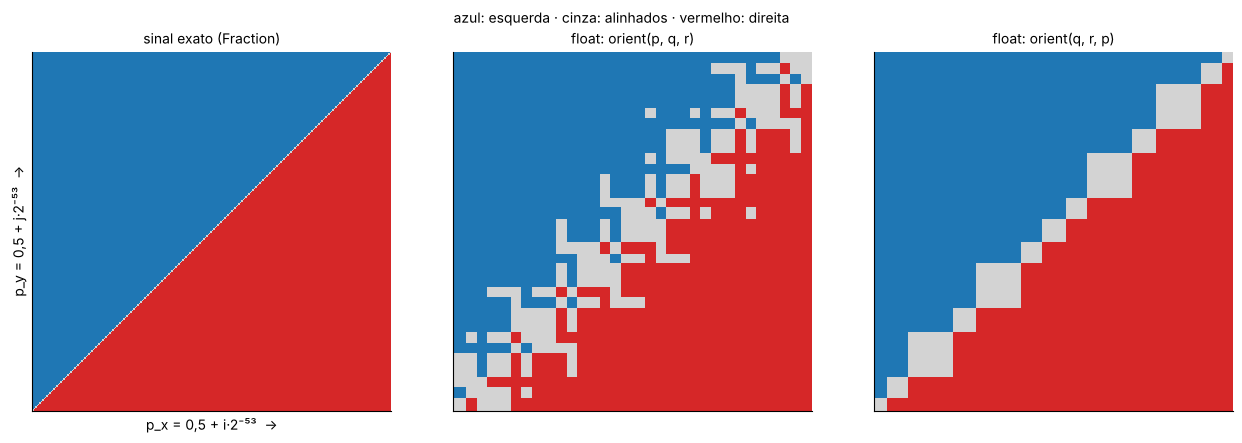

In [7]:
n, passo = 256, 2.0**-53
q0, r0 = (12.0, 12.0), (24.0, 24.0)
I, J = np.meshgrid(np.arange(n), np.arange(n))
PX, PY = 0.5 + I * passo, 0.5 + J * passo

sinal_float = np.sign(orient((PX, PY), q0, r0))
sinal_float_2 = np.sign(orient(q0, r0, (PX, PY)))          # a MESMA conta em aritmética real (rotação cíclica)
sinal_exato = np.zeros_like(sinal_float)
for i in range(n):
    for j in range(n):
        val = orient((Fraction(PX[j, i]), Fraction(PY[j, i])), (Fraction(12), Fraction(12)), (Fraction(24), Fraction(24)))
        sinal_exato[j, i] = (val > 0) - (val < 0)

discorda = np.mean(sinal_float != sinal_exato)
oposto = np.mean(sinal_float * sinal_exato < 0)
print(f"o sinal em float discorda do exato em {100 * discorda:.1f}% dos pontos")
print(f"   em {100 * np.mean((sinal_float == 0) & (sinal_exato != 0)):.1f}% o float diz 'alinhados' e não estão;  em {100 * oposto:.1f}% diz o lado ERRADO")
print(f"as duas fórmulas, iguais em aritmética real, discordam entre si em {100 * np.mean(sinal_float != sinal_float_2):.1f}% dos pontos")
print(f"pontos exatamente alinhados (sinal exato = 0): {100 * np.mean(sinal_exato == 0):.2f}%  (a diagonal p_x = p_y)")
confere("o sinal exato é antissimétrico em relação à diagonal", sinal_exato, -sinal_exato.T)

cores = plt.matplotlib.colors.ListedColormap(["tab:red", "lightgray", "tab:blue"])
fig, ax = plt.subplots(1, 3, figsize=(13, 4.3))
for a_, s_, t_ in zip(ax, [sinal_exato, sinal_float, sinal_float_2],
                      ["sinal exato (Fraction)", "float: orient(p, q, r)", "float: orient(q, r, p)"]):
    a_.imshow(s_, origin="lower", cmap=cores, vmin=-1, vmax=1, interpolation="nearest")
    a_.set_title(t_, fontsize=10); a_.set_xticks([]); a_.set_yticks([]); a_.grid(False)
ax[0].set_xlabel("p_x = 0,5 + i·2⁻⁵³  →"); ax[0].set_ylabel("p_y = 0,5 + j·2⁻⁵³  →")
fig.suptitle("azul: esquerda · cinza: alinhados · vermelho: direita", fontsize=10)
plt.tight_layout(); plt.show()

**Leitura.** O sinal exato é limpo: abaixo da diagonal, um lado; acima, o outro. O `float` produz um mosaico. Em quase um quinto dos pontos ele discorda da resposta exata, quase sempre dizendo "alinhados" quando não estão, e em cerca de 1% dando o **lado errado**. E duas maneiras de escrever o mesmo determinante, idênticas em aritmética real, discordam entre si em mais de 10% dos pontos.

Num algoritmo de fecho convexo, um lado errado pode produzir um "polígono" que se cruza, ou um laço infinito. As bibliotecas sérias (CGAL, os predicados de Shewchuk) resolvem o problema com **aritmética adaptativa**: fazem a conta em `float`, estimam o erro possível, e só refazem com aritmética exata quando o sinal está em dúvida. É a mesma estratégia `float` / `Fraction` do notebook I(a), aplicada só onde precisa.

> **Nota: por que pontos tão próximos?** Porque o problema real é a **quase colinearidade**, e ela aparece sozinha em dados de verdade: pontos de um mapa sobre uma avenida reta, vértices de uma malha fina, leituras de um sensor que anda em linha reta. A grade minúscula só torna o fenômeno visível.

---

## 6. Transformações do plano

**Translações: o grupo deste domínio.** Mover um objeto rígido sem girá-lo é somar um vetor a todos os seus pontos: $T_{\mathbf t}(p)=p+\mathbf t$. Compor translações é somar vetores, e a ordem não importa. É exatamente o domínio I com duas coordenadas: o grupo das translações do plano é $(\mathbb R^2,+)$, comutativo.

**Transformações lineares.** Uma matriz $2\times2$ leva vetores em vetores: $\mathbf v\mapsto\mathbf A\mathbf v$. Três fatos que a série vai usar:
- o **determinante** de $\mathbf A$ é o fator pelo qual ela multiplica as **áreas** (com sinal: negativo se espelha);
- uma **rotação** $\mathbf R_\theta=\begin{bmatrix}\cos\theta&-\sin\theta\\\sin\theta&\cos\theta\end{bmatrix}$ preserva distâncias e ângulos, e tem determinante 1;
- compor transformações é multiplicar matrizes, e **a ordem importa**: girar e depois esticar não é o mesmo que esticar e depois girar. Em ℝ², as rotações em torno da origem comutam entre si; misturadas com translações (domínio V) deixam de comutar.

det R(θ) = 1 ;  RᵀR = [[1, 0], [0, 1]]


R(θ1)R(θ2) − R(θ1+θ2) = [[0, 0], [0, 0]]  (rotações do plano comutam)
OK   área depois de 'estica' = det · área:  diferença máxima = 0.00e+00
OK   área depois de 'cisalha' = det · área:  diferença máxima = 0.00e+00
OK   área depois de 'gira 30°' = det · área:  diferença máxima = 0.00e+00
OK   área depois de 'espelha em x' = det · área:  diferença máxima = 0.00e+00

girar e depois cisalhar:
 [[1.616025 0.799038]
 [0.5      0.866025]] 
cisalhar e depois girar:
 [[0.866025 0.799038]
 [0.5      1.616025]] 
 → diferentes: a ordem importa


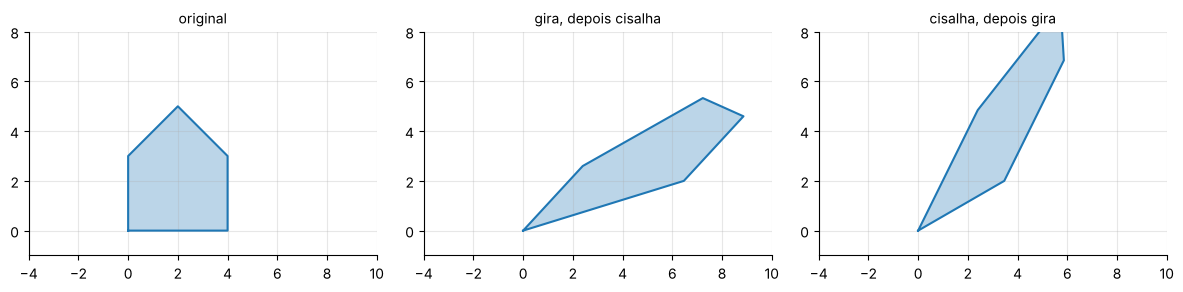

In [8]:
th = sp.Symbol("theta", real=True)
Rs = sp.Matrix([[sp.cos(th), -sp.sin(th)], [sp.sin(th), sp.cos(th)]])
print("det R(θ) =", sp.simplify(Rs.det()), ";  RᵀR =", sp.simplify(Rs.T * Rs).tolist())
t1, t2 = sp.symbols("theta1 theta2", real=True)
print("R(θ1)R(θ2) − R(θ1+θ2) =", sp.simplify(Rs.subs(th, t1) * Rs.subs(th, t2) - Rs.subs(th, t1 + t2)).tolist(), " (rotações do plano comutam)")

A_est = np.array([[2.0, 0.0], [0.0, 0.5]])                  # estica x, encolhe y
A_cis = np.array([[1.0, 1.5], [0.0, 1.0]])                  # cisalhamento
R30 = np.array([[np.cos(np.pi / 6), -np.sin(np.pi / 6)], [np.sin(np.pi / 6), np.cos(np.pi / 6)]])
casa_ = np.array(casa, float)
for nome, Am in [("estica", A_est), ("cisalha", A_cis), ("gira 30°", R30), ("espelha em x", np.diag([1.0, -1.0]))]:
    confere(f"área depois de '{nome}' = det · área", area_poligono(casa_ @ Am.T), np.linalg.det(Am) * area_poligono(casa_), tol=1e-12)
print("\ngirar e depois cisalhar:\n", A_cis @ R30, "\ncisalhar e depois girar:\n", R30 @ A_cis, "\n → diferentes: a ordem importa")

fig, ax = plt.subplots(1, 3, figsize=(12, 3.6))
for a_, (T, t_) in zip(ax, [(np.eye(2), "original"), (A_cis @ R30, "gira, depois cisalha"), (R30 @ A_cis, "cisalha, depois gira")]):
    pts = np.vstack([casa_, casa_[:1]]) @ T.T
    a_.fill(pts[:, 0], pts[:, 1], alpha=.3); a_.plot(pts[:, 0], pts[:, 1])
    a_.set_aspect("equal"); a_.set_xlim(-4, 10); a_.set_ylim(-1, 8); a_.set_title(t_, fontsize=10)
plt.tight_layout(); plt.show()

---

## 7. A interface de domínio em ℝ²

O domínio II é o grupo das translações do plano. A interface é a mesma do domínio I, agora com vetores de duas coordenadas:

| operação | em ℝ | em ℝ² |
|---|---|---|
| `compoe(g, h)` | $g+h$ | $\mathbf g+\mathbf h$ |
| `inverso(g)` | $-g$ | $-\mathbf g$ |
| `identidade` | $0$ | $(0,0)$ |
| `Exp(ξ)`, `Log(g)` | $\xi$, $g$ | $\boldsymbol\xi$, $\mathbf g$ |
| $x\boxplus\delta$, $\ y\boxminus x$ | $x+\delta$, $\ y-x$ | $\mathbf x+\boldsymbol\delta$, $\ \mathbf y-\mathbf x$ |

Os testes são **os mesmos** do notebook I(a), com os mesmos nomes. Uma conferência a mais mostra que ℝ² é, como grupo, o produto de duas cópias de ℝ: compor no plano é compor em cada eixo separadamente. Isso deixará de ser verdade no domínio V, em que a posição e a atitude se misturam.

In [9]:
class DominioReal:
    """Domínio I (repetido aqui para a comparação)."""
    nome = "ℝ"; dim = 1; identidade = 0.0
    def compoe(self, g, h): return g + h
    def inverso(self, g):   return -g
    def Exp(self, xi):      return float(xi)
    def Log(self, g):       return float(g)
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

class DominioR2:
    """Domínio II: o plano. Os movimentos são translações; compor é somar vetores."""
    nome = "ℝ²"
    dim = 2
    identidade = np.zeros(2)
    def compoe(self, g, h): return np.asarray(g, float) + np.asarray(h, float)
    def inverso(self, g):   return -np.asarray(g, float)
    def Exp(self, xi):      return np.array(xi, float)
    def Log(self, g):       return np.array(g, float)
    def mais(self, x, d):   return self.compoe(x, self.Exp(d))
    def menos(self, y, x):  return self.Log(self.compoe(self.inverso(x), y))

def testa_dominio(D, amostra, tol=1e-12):
    """Os mesmos testes do domínio I; servirão para os oito domínios."""
    g, h, k = amostra(), amostra(), amostra()
    print(f"domínio {D.nome}")
    confere("  associatividade da composição", D.menos(D.compoe(D.compoe(g, h), k), D.compoe(g, D.compoe(h, k))), 0, tol)
    confere("  identidade", D.menos(D.compoe(g, D.identidade), g), 0, tol)
    confere("  inverso", D.menos(D.compoe(g, D.inverso(g)), D.identidade), 0, tol)
    d = D.Log(amostra()) * 0.3
    confere("  Log(Exp(δ)) = δ", D.Log(D.Exp(d)), d, tol)
    confere("  (x ⊞ δ) ⊟ x = δ", D.menos(D.mais(g, d), g), d, tol)
    confere("  x ⊞ (y ⊟ x) = y", D.menos(D.mais(g, D.menos(h, g)), h), 0, tol)

R1, R2 = DominioReal(), DominioR2()
testa_dominio(R2, lambda: rng.normal(scale=10, size=2))

g, h = rng.normal(scale=10, size=2), rng.normal(scale=10, size=2)
confere("ℝ² = ℝ × ℝ: compor no plano = compor em cada eixo", R2.compoe(g, h), [R1.compoe(g[0], h[0]), R1.compoe(g[1], h[1])], tol=0)
confere("a composição comuta (o grupo é abeliano)", R2.compoe(g, h), R2.compoe(h, g), tol=0)

domínio ℝ²
OK     associatividade da composição:  diferença máxima = 0.00e+00
OK     identidade:  diferença máxima = 0.00e+00
OK     inverso:  diferença máxima = 0.00e+00
OK     Log(Exp(δ)) = δ:  diferença máxima = 0.00e+00
OK     (x ⊞ δ) ⊟ x = δ:  diferença máxima = 4.44e-16
OK     x ⊞ (y ⊟ x) = y:  diferença máxima = 0.00e+00
OK   ℝ² = ℝ × ℝ: compor no plano = compor em cada eixo:  diferença máxima = 0.00e+00
OK   a composição comuta (o grupo é abeliano):  diferença máxima = 0.00e+00


**Para pensar.** Se o domínio II é só "duas cópias do domínio I", por que ele merece um domínio inteiro? Porque as **medidas** misturam as coordenadas. A distância até um ponto, $\sqrt{x^2+y^2}$, e a direção, $\mathrm{atan2}(y,x)$, dependem das duas ao mesmo tempo, e são não lineares. Os sistemas de equações da etapa (b), o arrasto da etapa (c) (que depende do **módulo** da velocidade) e os sensores da etapa (d) são onde o plano deixa de ser duas retas.

---

## 8. Exercícios

1. **Ponto médio robusto.** Em `float`, $(p+q)/2$ e $p+(q-p)/2$ são a mesma conta? Procure pares de floats grandes (perto de `np.finfo(float).max`) em que uma delas transborda, e outros em que o resultado cai **fora** do segmento.
2. **Fecho convexo.** Implemente o algoritmo da "cadeia monótona" de Andrew (ordenar os pontos lexicograficamente e montar as metades inferior e superior com o teste `orient`). Teste com 1000 pontos aleatórios e confira o resultado com `scipy.spatial.ConvexHull`.
3. **Orientação com `Fraction`, só quando precisa.** Escreva `orient_robusto(p, q, r)`, que calcula em `float` e, se $|\mathrm{orient}|$ for menor que uma cota de erro (por exemplo $10^{-14}$ vezes a soma dos módulos dos dois produtos), refaz a conta com `Fraction`. Refaça a figura da seção 5 com ele. Quantas vezes a conta exata foi necessária?
4. **Os hiperbólicos.** Com $\alpha=+1$, mostre que $\tfrac12(1+j)$ e $\tfrac12(1-j)$ são **idempotentes** ($e^2=e$) e que o produto dos dois é zero. Conclua que, nas coordenadas $(a+b,\ a-b)$, o produto hiperbólico é o produto componente a componente.
5. **Área e determinante.** Mostre com o `sympy` que $\mathrm{orient}(\mathbf Ap,\mathbf Aq,\mathbf Ar)=\det(\mathbf A)\,\mathrm{orient}(p,q,r)$ para uma matriz $2\times2$ qualquer. O que isso diz sobre o efeito de um espelho no teste de orientação?